# SPHEREx ice maps — H2O, CO2, CO and OCN$^-$

Fits the ice bands in every pixel of a SPHEREx cube and turns them into column densities,
corrected for what the instrument does to a band it cannot resolve.

**How the bands are measured — the same fit for every ice**

* **Each ice in its own window, with its own baseline.** H2O in 2.42–3.82 $\mu$m, CO2 in
  4.00–4.45 $\mu$m, CO + OCN$^-$ in 4.45–4.85 $\mu$m. In each window in logspace the band(s) and a
  straight-line local baseline are fitted together, with the band amplitudes $\geq 0$.  The PAH 3.3/3.4 $\mu$m features are
  fitted first and removed from the spectrum.

* **Widths.** CO and OCN$^-$ are fixed (CO is unresolved by SPHEREx; OCN$^-$ is intrinsically
  ~26 cm$^{-1}$ wide). H2O (asymmetric Gaussian at 3.00 $\mu$m) and CO2 are free, but only within
  laboratory FWHM ranges — H2O 250–600 cm$^{-1}$, CO2 8–30 cm$^{-1}$ — broadened by the SPHEREx
  line spread (nominal $\lambda/R$ for the lower limit, the cube's broader effective line spread
  for the upper limit).
* **Band centres** are the laboratory wavelengths (H2O fixed at 3.00 $\mu$m) plus one shift you set
  for CO2, CO and OCN$^-$ (`band_shift_um`, header BANDSHFT); SPHEREx wavelengths can sit
  ~0.01 $\mu$m off.
* **OCN$^-$** is in the CO fit in every pixel, so it cannot borrow depth from CO or the reverse;
  its maps are kept only where CO is detected. CO is kept only where H2O is detected.


**What comes out**

`ice_maps_<target>.fits` (column, error, peak $\tau$, S/N, peak wavelength and correction flag per
ice, plus the baselines and the optical-depth cube), the same as a flat table in
`ice_maps_<target>.csv`, a PNG per map, and `continuum_diagnostics_<target>.pdf` with one page per
pixel — a random sample of the ice pixels plus the pixels where each band is strongest.

Run the cells in order.

## 1. Setup and band profiles

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import curve_fit
from scipy.optimize import lsq_linear 
import warnings

from astropy.visualization import ImageNormalize, AsymmetricPercentileInterval, LinearStretch

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)



# ==========================================
# HELPER FUNCTIONS
# ==========================================

def gaussian(x, amp, cen, wid):
    return amp * np.exp(-(x - cen)**2 / (2 * wid**2))

def double_gaussian(x, amp1, cen1, wid1, amp2, cen2, wid2):
    return gaussian(x, amp1, cen1, wid1) + gaussian(x, amp2, cen2, wid2)

def asymmetric_gaussian(x, amp, cen, wid_left, wid_right):
    y = np.zeros_like(x)
    left_mask = x <= cen
    right_mask = x > cen
    
    if np.any(left_mask):
        y[left_mask] = amp * np.exp(-(x[left_mask] - cen)**2 / (2 * wid_left**2))
    if np.any(right_mask):
        y[right_mask] = amp * np.exp(-(x[right_mask] - cen)**2 / (2 * wid_right**2))
        
    return y

## 2. Band centres and widths

Laboratory centres (plus `band_shift_um` for CO2, CO and OCN$^-$) and the fixed CO / OCN$^-$ widths.


In [2]:
# Laboratory band centres (um) and the band widths at the SPHEREx resolution (sigma, um, from the
# simulated instrument).  CO and OCN- widths are fixed in the fits; CO2_SIGMA is only the start
# value of the free CO2 width (see section 4).
CO2_CEN = 4.268               # laboratory centres (um)
CO_CEN = 4.673
OCN_CEN = 4.617               # OCN- (XCN), 2165 cm-1: the band on the blue side of CO
CO2_SIGMA = 0.0236            # widths (um) at the SPHEREx resolution, from the simulation
CO_SIGMA = 0.0211             # CO width: fixed
OCN_SIGMA = 0.030             # OCN- is intrinsically broad (~26 cm-1): fixed


def band_shape(shift=0.0):
    """Band centres (laboratory + shift, um) and widths used in the fits."""
    return dict(CO2_cen=CO2_CEN + shift, CO2_sig=CO2_SIGMA, CO_cen=CO_CEN + shift, CO_sig=CO_SIGMA,
                OCN_cen=OCN_CEN + shift, shift=shift)


## 3. Helpers: column densities, peak wavelengths and the 3.3 / 3.4 $\mu$m features

The PAH features are fitted on their own line between 3.15 and 3.55 $\mu$m and subtracted before the
ice fits.


In [3]:
def gaussian_column(amp, cen, wid, band_strength):
    """Analytic column of a Gaussian in wavelength: N = tau * sigma * sqrt(2 pi) * 1e4 / cen^2 / A."""
    return amp * wid * np.sqrt(2 * np.pi) * 1e4 / cen ** 2 / band_strength


def peak_wavelength(tau, waves, w_min, w_max):
    """Wavelength of the optical-depth peak: parabola through the highest point and its two
    neighbours (sub-grid precision); NaN if the peak is at the window edge."""
    m = np.where((waves >= w_min) & (waves <= w_max) & np.isfinite(tau))[0]
    if m.size < 3:
        return np.nan
    i = m[np.argmax(tau[m])]
    if i == m[0] or i == m[-1]:
        return float(waves[i])
    x, y = waves[i - 1:i + 2], tau[i - 1:i + 2]
    den = (y[0] - 2 * y[1] + y[2])
    if den >= 0:
        return float(waves[i])
    h = 0.5 * (y[0] - y[2]) / den
    return float(waves[i] + np.clip(h, -1, 1) * 0.5 * (x[2] - x[0]))


def evaluate_and_fit_pah_features(waves, flux, subtract_pah=True, fit_34_feature=True, thresh_33=3.0, thresh_34=3.0):
    """
    Evaluates residual emission against local noise thresholds and conditionally fits
    3.3 um and/or 3.4 um features only when signal-to-noise requirements are met.
    """
    a_pah, c_pah, w_pah = 0.0, 3.29, 0.04
    a_34, c_34, w_34 = 0.0, 3.40, 0.03
    
    if not subtract_pah:
        return a_pah, c_pah, w_pah, a_34, c_34, w_34

    pah_mask = (waves >= 3.15) & (waves <= 3.55) & ~np.isnan(flux)
    if np.sum(pah_mask) < 5:
        return a_pah, c_pah, w_pah, a_34, c_34, w_34

    lw, lf = waves[pah_mask], flux[pah_mask]
    baseline = np.interp(lw, [lw[0], lw[-1]], [lf[0], lf[-1]])
    pah_only_flux = lf - baseline

    # Local noise estimate from off-peak continuum bands
    noise_mask = ((lw >= 3.15) & (lw <= 3.22)) | ((lw >= 3.50) & (lw <= 3.55))
    local_noise = np.nanstd(pah_only_flux[noise_mask]) if np.sum(noise_mask) > 2 else 1e-5
    if local_noise <= 0 or np.isnan(local_noise):
        local_noise = 1e-5

    # Check 3.3 um peak (3.25 - 3.35 um)
    m33 = (lw >= 3.25) & (lw <= 3.35)
    peak_33 = np.nanmax(pah_only_flux[m33]) if np.any(m33) else 0.0
    fit_33_needed = peak_33 > (thresh_33 * local_noise)

    # Check 3.4 um peak (3.38 - 3.48 um)
    m34 = (lw >= 3.38) & (lw <= 3.48)
    peak_34 = np.nanmax(pah_only_flux[m34]) if np.any(m34) else 0.0
    fit_34_needed = fit_34_feature and (peak_34 > (thresh_34 * local_noise))

    # Conditional Fitting Decision Tree
    if fit_33_needed and fit_34_needed:
        try:
            popt_2g, _ = curve_fit(
                double_gaussian, lw, pah_only_flux,
                p0=[peak_33, 3.29, 0.04, peak_34, 3.40, 0.03],
                bounds=([0, 3.25, 0.02, 0, 3.37, 0.015], 
                        [np.nanmax(flux) * 3, 3.35, 0.15, np.nanmax(flux) * 2, 3.46, 0.08])
            )
            a_pah, c_pah, w_pah, a_34, c_34, w_34 = popt_2g
        except Exception:
            pass
    elif fit_33_needed:
        try:
            popt_33, _ = curve_fit(
                gaussian, lw, pah_only_flux,
                p0=[peak_33, 3.29, 0.04],
                bounds=([0, 3.25, 0.02], [np.nanmax(flux) * 3, 3.35, 0.15])
            )
            a_pah, c_pah, w_pah = popt_33
        except Exception:
            pass
    elif fit_34_needed:
        try:
            popt_34, _ = curve_fit(
                gaussian, lw, pah_only_flux,
                p0=[peak_34, 3.40, 0.03],
                bounds=([0, 3.37, 0.015], [np.nanmax(flux) * 2, 3.46, 0.08])
            )
            a_34, c_34, w_34 = popt_34
        except Exception:
            pass

    return a_pah, c_pah, w_pah, a_34, c_34, w_34

In [4]:
# =====================================================================================
# ONE FIT FOR EVERY ICE  (2026-11-18)
# Every ice is fitted the same way, in its own window, on y = -ln F (PAH features removed):
#     y = sum_k a_k P_k(lambda) + c0 + c1 (lambda - lambda_ref)
# i.e. the band(s) and a straight-line LOCAL BASELINE fitted together, band amplitudes >= 0.
# Uncertainties: the scatter of the data about the fitted model in the window (the standard
# least-squares error).  The noise of the local baseline (scatter about a straight line through
# the continuum windows) is kept as a diagnostic map; with only ~5 continuum channels around CO
# it is often too small, and as the error it gave ~4 % false CO detections (0.2 % with this one).
# Widths: CO and OCN- fixed (CO is unresolved by SPHEREx; OCN- is intrinsically ~26 cm-1);
# H2O and CO2 free, but only within the range of LABORATORY band widths, broadened by the
# SPHEREx line-spread function.  The same function measures the maps and the simulations.
# =====================================================================================
from scipy.optimize import least_squares

STRENGTH = {'H2O': 2.0e-16, 'CO2': 7.6e-17, 'CO': 1.1e-17}     # cm molecule-1
H2O_CEN = 3.00                                                  # um, fixed
FWHM_FAC = np.sqrt(8 * np.log(2))                               # FWHM / sigma of a Gaussian

# SPHEREx bands: (lambda_min, lambda_max, nominal resolving power R)
SPHEREX_BANDS = ((0.75, 1.09, 39), (1.10, 1.62, 41), (1.63, 2.41, 41), (2.42, 3.82, 35),
                 (3.83, 4.41, 112), (4.42, 5.00, 130))
# The cube's line spread is broader than lambda / R (the spectral resampling of the cube builder).
# CO is unresolved in the laboratory (FWHM 2-10 cm-1, < 0.002 um), so its simulated width IS the
# line spread at 4.67 um; that fixes the broadening factor applied to every band.
LSF_FACTOR = CO_SIGMA * FWHM_FAC / (CO_CEN / 130.0)


def lsf_fwhm(lam):
    """FWHM (um) of the cube's line-spread function at wavelength lam."""
    R = next((r for lo, hi, r in SPHEREX_BANDS if lo <= lam <= hi), 41)
    return LSF_FACTOR * lam / R


def lab_width_range(lam, fwhm_cm1):
    """Observed FWHM range (um): the laboratory FWHM range (cm-1) in wavelength, added in
    quadrature to the SPHEREx line spread -- the nominal lambda / R for the lower limit and the
    broader effective line spread of the cube (LSF_FACTOR) for the upper limit, since the
    resampling broadening is calibrated only at 4.67 um (CO)."""
    lab = np.asarray(fwhm_cm1, float) * lam ** 2 / 1e4
    nominal = lsf_fwhm(lam) / LSF_FACTOR
    return (float(np.hypot(lab[0], nominal)), float(np.hypot(lab[1], lsf_fwhm(lam))))


# Laboratory FWHM ranges (cm-1) -- CHECK against your preferred references:
#   H2O 3 um O-H stretch: ~250 (crystalline) to ~450 cm-1 (amorphous; Hagen et al. 1981;
#       Gerakines et al. 1995).  Upper limit raised to 600 cm-1: interstellar 3 um bands carry a
#       long-wavelength wing (3.2-3.6 um; ammonia hydrates, scattering by large grains) that the
#       Serpens pixels need (53 % sat at 450 cm-1).  sigma_red / sigma_blue = H2O_ASYM.
#   CO2 4.27 um stretch: ~8 (apolar CO:CO2) to ~30 cm-1 (polar H2O:CO2 mixtures; Ehrenfreund et al.
#       1996, 1997; Gerakines et al. 1995).
LAB_FWHM_CM1 = {'H2O': (250.0, 600.0), 'CO2': (8.0, 30.0)}
H2O_ASYM = (1.0, 2.5)

# Fit window and continuum (local-baseline) windows of each ice (um)
ICE_WINDOWS = {
    'H2O': dict(window=(2.42, 3.82), cont=((2.42, 2.60), (3.60, 3.82))),
    'CO2': dict(window=(4.00, 4.45), cont=((4.00, 4.14), (4.39, 4.45))),
    'CO':  dict(window=(4.45, 4.85), cont=((4.45, 4.53), (4.75, 4.85))),
}
_LAM_FINE = np.linspace(2.0, 4.6, 2601)


def baseline_noise(waves, y, cont):
    """Noise of one spectrum around one band: the scatter (ddof = 2) of y = -ln F about a straight
    line through the continuum windows on both sides, after one 3-sigma clip."""
    m = np.zeros(len(waves), bool)
    for lo, hi in cont:
        m |= (waves >= lo) & (waves <= hi)
    m &= np.isfinite(y)
    if m.sum() < 4:
        return np.nan
    x, v = waves[m], y[m]
    r = v - np.polyval(np.polyfit(x, v, 1), x)
    s = np.std(r, ddof=2)
    k = np.abs(r) < 3 * s
    if 4 <= k.sum() < m.sum():
        r = v[k] - np.polyval(np.polyfit(x[k], v[k], 1), x[k])
        s = np.std(r, ddof=2)
    return float(s)


def _band_names(ice):
    return {'H2O': ['H2O'], 'CO2': ['CO2'], 'CO': ['CO', 'OCN']}[ice]


def band_profiles(ice, lam, shape, q):
    """Unit-amplitude band profiles of one ice on `lam`, for the free width parameters q
    (H2O: [FWHM, sigma_red / sigma_blue]; CO2: [FWHM]; CO: none).  Returns (profiles, widths)."""
    lam = np.asarray(lam, float)
    if ice == 'H2O':
        fw, asym = q
        sl = 2 * fw / FWHM_FAC / (1 + asym)
        return [asymmetric_gaussian(lam, 1.0, H2O_CEN, sl, asym * sl)], dict(H2O_left=sl, H2O_right=asym * sl)
    if ice == 'CO2':
        s = q[0] / FWHM_FAC
        return [gaussian(lam, 1.0, shape['CO2_cen'], s)], dict(CO2=s)
    return ([gaussian(lam, 1.0, shape['CO_cen'], shape['CO_sig']),
             gaussian(lam, 1.0, shape['OCN_cen'], OCN_SIGMA)], dict(CO=shape['CO_sig']))


def width_bounds(ice, shape):
    """Start values and bounds of the free width parameters (None for CO)."""
    if ice == 'H2O':
        lo, hi = lab_width_range(H2O_CEN, LAB_FWHM_CM1['H2O'])
        return np.array([0.5 * (lo + hi), 1.5]), np.array([lo, H2O_ASYM[0]]), np.array([hi, H2O_ASYM[1]])
    if ice == 'CO2':
        lo, hi = lab_width_range(shape['CO2_cen'], LAB_FWHM_CM1['CO2'])
        return np.array([np.clip(CO2_SIGMA * FWHM_FAC, lo, hi)]), np.array([lo]), np.array([hi])
    return None


def band_column(ice, amp, widths, shape):
    """Column density (cm-2) of the main band of `ice`."""
    if not (amp > 0):
        return np.nan
    if ice == 'H2O':
        tau = asymmetric_gaussian(_LAM_FINE, amp, H2O_CEN, widths['H2O_left'], widths['H2O_right'])
        return float(np.trapezoid(tau * 1e4 / _LAM_FINE ** 2, _LAM_FINE) / STRENGTH['H2O'])
    if ice == 'CO2':
        return float(gaussian_column(amp, shape['CO2_cen'], widths['CO2'], STRENGTH['CO2']))
    return float(gaussian_column(amp, shape['CO_cen'], shape['CO_sig'], STRENGTH['CO']))


def fit_ice_window(waves, y, ice, shape):
    """The fit of one ice in one spectrum (see the cell header).  Returns a dict: tau, err, snr
    (main band; errors from the scatter about the model), N, Nerr, amps {band: (amp, err)},
    widths, noise (local-baseline noise, diagnostic), resid_rms, win
    (channels of the window), base_flux, tau_local (y minus the baseline, in the window) and
    model (the fitted bands on all channels); None if the window cannot be fitted."""
    cfg = ICE_WINDOWS[ice]
    win = (waves >= cfg['window'][0]) & (waves <= cfg['window'][1])
    m = win & np.isfinite(y)
    if m.sum() < 8:
        return None
    noise = baseline_noise(waves, y, cfg['cont'])
    if not (np.isfinite(noise) and noise > 0):
        return None
    x, v = waves[m], y[m]
    ref = 0.5 * (cfg['window'][0] + cfg['window'][1])
    names = _band_names(ice)
    nb = len(names)
    lo_b = np.r_[np.zeros(nb), -np.inf, -np.inf]

    def design(q):
        prof, _ = band_profiles(ice, x, shape, q)
        return np.column_stack(prof + [np.ones_like(x), x - ref])

    def solve(A):
        p = np.linalg.lstsq(A, v, rcond=None)[0]
        if (p[:nb] < 0).any():
            p = lsq_linear(A, v, bounds=(lo_b, np.inf), method='bvls').x
        return p

    wb = width_bounds(ice, shape)
    if wb is None:                              # CO + OCN-: fixed widths, one linear solve
        q = np.array([])
        A = design(q)
        p = solve(A)
        J = A
    else:                                       # H2O, CO2: widths free within the lab range
        q0, lb, ub = wb
        try:
            q = least_squares(lambda qq: v - design(qq) @ solve(design(qq)), q0,
                              bounds=(lb, ub), x_scale=q0).x
        except Exception:
            q = q0
        A = design(q)
        p = solve(A)
        cols = [A]
        for k in range(len(q)):                 # model derivative in each width parameter
            dq = np.zeros_like(q)
            dq[k] = 1e-4 * max(abs(q[k]), 1e-3)
            cols.append(((design(q + dq) - design(q - dq)) @ p / (2 * dq[k]))[:, None])
        J = np.column_stack(cols)
    resid = v - A @ p
    s_res = np.sqrt(resid @ resid / max(len(v) - J.shape[1], 1))    # scatter about the model
    cov = s_res ** 2 * np.linalg.pinv(J.T @ J)
    err = np.sqrt(np.clip(np.diag(cov)[:nb], 0, None))
    amps = {n: (float(p[k]), float(err[k])) for k, n in enumerate(names)}
    prof_all, widths = band_profiles(ice, waves, shape, q)
    model = np.sum([p[k] * prof_all[k] for k in range(nb)], axis=0)
    base_y = np.full(waves.shape, np.nan)
    base_y[win] = p[nb] + p[nb + 1] * (waves[win] - ref)
    tau_local = np.where(win, y - base_y, np.nan)
    a, e = amps[names[0]]
    N = band_column(ice, a, widths, shape)
    return dict(tau=a, err=e, snr=(a / e if e > 0 else 0.0), N=N,
                Nerr=(e / a * N if a > 0 else np.nan), amps=amps, widths=widths, noise=noise,
                resid_rms=float(s_res),
                win=win, base_flux=np.exp(-base_y), tau_local=tau_local, model=model)


def measure_spectrum(waves, flux, shape, subtract_pah=True, fit_34_feature=True,
                     thresh_33=3.0, thresh_34=3.0):
    """Everything measured in one spectrum: the 3.3 / 3.4 um features (subtracted first), then
    fit_ice_window for H2O, CO2 and CO + OCN-.  Used for every map pixel and every simulation."""
    waves = np.asarray(waves, float)
    flux = np.asarray(flux, float)
    if np.sum(np.isfinite(flux) & (flux > 0)) < 5:
        return None
    pah = evaluate_and_fit_pah_features(waves, flux, subtract_pah=subtract_pah,
                                        fit_34_feature=fit_34_feature, thresh_33=thresh_33,
                                        thresh_34=thresh_34)
    a_pah, c_pah, w_pah, a_34, c_34, w_34 = pah
    pah33 = gaussian(waves, a_pah, c_pah, w_pah) if a_pah > 0 else np.zeros_like(waves)
    pah34 = gaussian(waves, a_34, c_34, w_34) if a_34 > 0 else np.zeros_like(waves)
    rest = flux - pah33 - pah34
    y = -np.log(np.where(rest > 0, rest, np.nan))
    out = dict(pah=pah, pah33=pah33, pah34=pah34, y=y)
    model = np.zeros_like(waves)
    for ice in ICE_WINDOWS:
        f = fit_ice_window(waves, y, ice, shape)
        out[ice] = f
        if f is not None:
            model = model + f['model']
    out['model_total'] = model
    return out


_s = band_shape(0.0)
for _ice in ('H2O', 'CO2'):
    _c = H2O_CEN if _ice == 'H2O' else _s['CO2_cen']
    _lo, _hi = lab_width_range(_c, LAB_FWHM_CM1[_ice])
    print(f"{_ice}: lab FWHM {LAB_FWHM_CM1[_ice][0]:.0f}-{LAB_FWHM_CM1[_ice][1]:.0f} cm-1 -> observed FWHM "
          f"{_lo:.3f}-{_hi:.3f} um (sigma {_lo / FWHM_FAC:.4f}-{_hi / FWHM_FAC:.4f}); LSF FWHM {lsf_fwhm(_c):.3f} um")
print(f"CO fixed sigma {CO_SIGMA} um, OCN- fixed sigma {OCN_SIGMA} um; LSF factor {LSF_FACTOR:.2f} x lambda/R")


H2O: lab FWHM 250-600 cm-1 -> observed FWHM 0.241-0.553 um (sigma 0.1022-0.2348); LSF FWHM 0.118 um
CO2: lab FWHM 8-30 cm-1 -> observed FWHM 0.041-0.076 um (sigma 0.0173-0.0322); LSF FWHM 0.053 um
CO fixed sigma 0.0211 um, OCN- fixed sigma 0.03 um; LSF factor 1.38 x lambda/R


## 5. Building the maps

`process_datacube` runs everything: the per-pixel loop (`measure_spectrum`: PAH features, then
H2O, CO2 and CO + OCN$^-$ in their own windows), the detection masks, the correction, and the
outputs.

Useful arguments: `tau_thresholds` and `snr_thresholds` (detection per ice), `co_requires_h2o`,
`band_shift_um` (shift added to the laboratory CO2, CO and OCN$^-$ centres; −0.012 for the Serpens
NIRCam cube, 0.0 = laboratory), `bin_factor` (bin the cube before anything else) and `correction`.


In [5]:
# ==========================================
# MAIN PROCESSING FUNCTION
# ==========================================

def process_datacube(cube_path, output_fits="ice_maps.fits", 
                     output_png_base="ice_maps", output_diag="continuum_diagnostics.pdf",
                     subtract_pah=True, fit_34_feature=True, 
                     thresh_33=3.0, thresh_34=3.0, 
                     bin_factor=1, 
                     tau_thresholds={'H2O': 0.05, 'CO2': 0.01, 'CO': 0.01},
                     snr_thresholds={'H2O': 3.0, 'CO2': 3.0, 'CO': 3.0},
                     correction='measured',
                     co_requires_h2o=True, band_shift_um=0.0): 
    
    print(f"Loading datacube: {cube_path}")
    
    with fits.open(cube_path) as hdul:
        data = hdul[0].data  
        header = hdul[0].header
        
        if 'WAVELENGTHS' in hdul:
            waves = hdul['WAVELENGTHS'].data
        else:
            n_waves = header['NAXIS3']
            waves = header['CRVAL3'] + (np.arange(1, n_waves + 1) - header['CRPIX3']) * header['CDELT3']

    flux_unit = header.get('BUNIT', 'MJy/sr')

    print("Trimming data to 1.4 - 5.0 um...")
    wave_mask = (waves >= 1.4) & (waves <= 5.0)
    waves = waves[wave_mask]
    data = data[wave_mask, :, :]
    
    nz, ny, nx = data.shape
    
    if bin_factor > 1:
        print(f"Binning spatial pixels by {bin_factor}x{bin_factor}...")
        new_ny = ny // bin_factor
        new_nx = nx // bin_factor
        data = data[:, :new_ny * bin_factor, :new_nx * bin_factor]
        data = data.reshape(nz, new_ny, bin_factor, new_nx, bin_factor).mean(axis=(2, 4))
        ny, nx = new_ny, new_nx
        for _k in ('CRPIX1', 'CRPIX2'):
            if _k in header: header[_k] = (header[_k] - 0.5) / bin_factor + 0.5
        for _k in ('CDELT1', 'CDELT2', 'CD1_1', 'CD1_2', 'CD2_1', 'CD2_2'):
            if _k in header: header[_k] *= bin_factor

    ices = {
        'H2O': (2.6, 4, 2.0e-16),
        'CO2': (4.1, 4.4, 7.6e-17),
        'CO':  (4.45, 4.8, 1.1e-17)
    }
    
    maps = {ice: np.full((ny, nx), np.nan) for ice in ices}
    maps_err = {ice: np.full((ny, nx), np.nan) for ice in ices}
    maps_tau_peak = {ice: np.full((ny, nx), np.nan) for ice in ices} 
    maps_snr = {ice: np.full((ny, nx), np.nan) for ice in ices}      # fitted peak / its error
    maps_lampeak = {ice: np.full((ny, nx), np.nan) for ice in ices}  # observed peak wavelength (um)
    co_wid_map = np.full((ny, nx), np.nan)                           # CO sigma (um)
    co2_wid_map = np.full((ny, nx), np.nan)                          # fitted CO2 sigma (um)
    ocn_tau_map = np.full((ny, nx), np.nan)     # OCN- (XCN) band at 4.617 um: peak tau
    ocn_snr_map = np.full((ny, nx), np.nan)     # ... and its S/N
    
    maps['PAH_3.3'] = np.full((ny, nx), np.nan)
    maps['PAH_3.4'] = np.full((ny, nx), np.nan)
    maps['Flux_Ratio'] = np.full((ny, nx), np.nan) 
        
    tau_raw_cube = np.full_like(data, np.nan)        # tau of each band against its own local baseline
    tau_corr_cube = np.full_like(data, np.nan)       # the fitted band models
    base_cube = np.full_like(data, np.nan)           # local baselines (flux), each only in its window
    wid = {k: np.full((ny, nx), np.nan) for k in ('H2O_left', 'H2O_right', 'CO2', 'CO')}   # sigma (um)
    noise_maps = {ice: np.full((ny, nx), np.nan) for ice in ices}   # local-baseline noise (tau)

    w15 = (waves >= 1.42) & (waves <= 1.58)          # flux-ratio map: 1.5 um flux / its median
    med_f15 = float(np.nanmedian(data[w15])) if w15.any() else np.nan

    nu = 10000.0 / waves
    sort_idx = np.argsort(nu)
    nu_sorted = nu[sort_idx]

    fit_ranges = {                                   # where the observed peak is looked for
        'H2O': (2.60, 3.82),
        'CO2': (4.10, 4.40),
        'CO':  (4.55, 4.75)
    }
    shape = band_shape(band_shift_um)  # laboratory centres + the shift you set
    print(f"Band shift: {band_shift_um:+.4f} um (CO2, CO, OCN- centres); H2O centre {H2O_CEN} um")
    for _ice in ('H2O', 'CO2'):
        _lo, _hi = lab_width_range(H2O_CEN if _ice == 'H2O' else shape['CO2_cen'], LAB_FWHM_CM1[_ice])
        print(f"    {_ice}: FWHM free within {_lo:.3f}-{_hi:.3f} um (lab {LAB_FWHM_CM1[_ice]} cm-1 + LSF)")
    print(f"    CO sigma {shape['CO_sig']} um, OCN- sigma {OCN_SIGMA} um (fixed)")

    print(f"Processing {ny}x{nx} spatial pixels...")
    for y in range(ny):
        for x in range(nx):
            flux = data[:, y, x]
            r = measure_spectrum(waves, flux, shape, subtract_pah=subtract_pah,
                                 fit_34_feature=fit_34_feature, thresh_33=thresh_33, thresh_34=thresh_34)
            if r is None:
                continue
            if r['pah'][0] > 0:
                maps['PAH_3.3'][y, x] = np.trapezoid(r['pah33'][sort_idx], x=nu_sorted)
            if r['pah'][3] > 0:
                maps['PAH_3.4'][y, x] = np.trapezoid(r['pah34'][sort_idx], x=nu_sorted)
            for ice in ('H2O', 'CO2', 'CO'):
                f = r[ice]
                if f is None:
                    continue
                maps_tau_peak[ice][y, x] = f['tau']
                maps_snr[ice][y, x] = f['snr']
                noise_maps[ice][y, x] = f['noise']
                if f['tau'] > 0:
                    maps[ice][y, x], maps_err[ice][y, x] = f['N'], f['Nerr']
                tau_raw_cube[f['win'], y, x] = f['tau_local'][f['win']]
                base_cube[f['win'], y, x] = f['base_flux'][f['win']]
                maps_lampeak[ice][y, x] = peak_wavelength(np.nan_to_num(f['tau_local'], nan=0.0),
                                                          waves, *fit_ranges[ice])
                for k, w_ in f['widths'].items():
                    wid[k][y, x] = w_
                if ice == 'CO':
                    ocn_tau_map[y, x], _e = f['amps']['OCN']
                    ocn_snr_map[y, x] = ocn_tau_map[y, x] / _e if _e > 0 else 0.0
            tau_corr_cube[:, y, x] = r['model_total']
            f15 = np.nanmedian(flux[w15]) if w15.any() else np.nan
            if med_f15 > 0 and f15 > 0:
                maps['Flux_Ratio'][y, x] = f15 / med_f15
        if (y + 1) % 10 == 0:
            print(f"    Row {y + 1}/{ny} complete")

    # CO ice only where H2O ice is detected; OCN- only where CO is
    det_h2o = (maps_tau_peak['H2O'] > (tau_thresholds.get('H2O') or 0.0)) & \
              (maps_snr['H2O'] >= snr_thresholds.get('H2O', 0))
    allowed = det_h2o if co_requires_h2o else np.ones((ny, nx), bool)
    co_tau_min, co_snr_min = (tau_thresholds.get('CO') or 0.0), snr_thresholds.get('CO', 0)
    co_done = (maps_tau_peak['CO'] > co_tau_min) & (maps_snr['CO'] >= co_snr_min) & allowed
    print(f"    H2O detected in {int(det_h2o.sum())} pixels, CO in {int(co_done.sum())}")
    ocn_tau_map[~co_done], ocn_snr_map[~co_done] = np.nan, np.nan
    co_wid_map, co2_wid_map = wid['CO'], wid['CO2']
    for ice in ('H2O', 'CO2', 'CO'):
        print(f"    {ice}: median local-baseline noise {np.nanmedian(noise_maps[ice]):.3f} (tau)")

    # ==========================================
    # SECOND-PASS: DIAGNOSTIC PLOTTING
    # ==========================================
    # which pixels to draw: a random sample of the ice pixels, plus the pixels where each band is
    # strongest, so that every fit in the model can be seen on a page (a random sample of the H2O
    # pixels shows CO on ~20 % of the pages and OCN- on ~2 %)
    h2o_plot_threshold = tau_thresholds.get('H2O', 0.05)
    valid_y, valid_x = np.where(maps_tau_peak['H2O'] > h2o_plot_threshold)
    pages, seen = [], set()
    if len(valid_y):
        rng = np.random.default_rng(0)
        for i in rng.choice(len(valid_y), size=min(len(valid_y), 40), replace=False):
            pages.append((int(valid_y[i]), int(valid_x[i]), 'random ice pixel'))
        for name, strength, n in (('deepest CO', np.where(co_done, maps_tau_peak['CO'], -np.inf), 20),
                                  ('strongest OCN-', np.where(np.isfinite(ocn_snr_map), ocn_snr_map, -np.inf), 20),
                                  ('deepest CO2', np.where(np.isfinite(maps_tau_peak['CO2']),
                                                           maps_tau_peak['CO2'], -np.inf), 20)):
            flat = strength.ravel()
            for i in np.argsort(flat)[::-1][:n]:
                if np.isfinite(flat[i]):
                    pages.append((int(i // nx), int(i % nx), name))
        pages = [p for p in pages if not (p[:2] in seen or seen.add(p[:2]))]

    with PdfPages(output_diag) as pdf:
        if pages:
            for y, x, why in pages:
                flux = data[:, y, x]
                r = measure_spectrum(waves, flux, shape, subtract_pah=subtract_pah,
                                     fit_34_feature=fit_34_feature, thresh_33=thresh_33, thresh_34=thresh_34)
                if r is None:
                    continue
                t_h2o = maps_tau_peak['H2O'][y, x]
                t_co2 = maps_tau_peak['CO2'][y, x]
                t_co = maps_tau_peak['CO'][y, x] if co_done[y, x] else 0.0
                t_ocn = ocn_tau_map[y, x] if np.isfinite(ocn_tau_map[y, x]) else 0.0
                fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
                for ax in (ax1, ax2):
                    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=10)
                    ax.grid(True, linestyle=':', alpha=0.45)
                ax1.plot(waves, flux, label='Observed Flux', color='black', drawstyle='steps-mid', linewidth=1)
                cols = {'H2O': 'darkcyan', 'CO2': 'purple', 'CO': 'darkorange'}
                for ice, c in cols.items():              # each ice: its own window and baseline
                    f = r[ice]
                    if f is None:
                        continue
                    ax1.plot(waves[f['win']], f['base_flux'][f['win']], color=c, linewidth=1.6,
                             label=f'{ice} baseline')
                    for lo, hi in ICE_WINDOWS[ice]['cont']:
                        ax1.axvspan(lo, hi, color=c, alpha=0.10)
                    ax2.plot(waves[f['win']], f['tau_local'][f['win']], color='black', drawstyle='steps-mid',
                             linewidth=1.2, label=r'$\tau$ (local baselines)' if ice == 'H2O' else None)
                    ax2.axvspan(*ICE_WINDOWS[ice]['window'], color=c, alpha=0.06)
                fh = r['H2O']
                if fh is not None:
                    _pw = (waves > 3.1) & (waves < 3.6)
                    bp = fh['base_flux']
                    if r['pah'][0] > 0:
                        ax1.fill_between(waves[_pw], bp[_pw], (bp + r['pah33'])[_pw], color='forestgreen',
                                         alpha=0.3, lw=0, label=r'PAH $3.3\,\mu\mathrm{m}$')
                    if r['pah'][3] > 0:
                        ax1.fill_between(waves[_pw], bp[_pw], (bp + r['pah34'])[_pw], color='mediumseagreen',
                                         alpha=0.3, lw=0, label=r'PAH/Aliphatic $3.4\,\mu\mathrm{m}$')
                    w_ = fh['widths']
                    ax2.plot(waves, asymmetric_gaussian(waves, max(t_h2o, 0), H2O_CEN, w_['H2O_left'], w_['H2O_right']),
                             label=r'$\mathrm{H_2O}$ Ice Fit', color='darkcyan', linewidth=1.8)
                if r['CO2'] is not None:
                    ax2.plot(waves, gaussian(waves, max(t_co2, 0), shape['CO2_cen'], r['CO2']['widths']['CO2']),
                             label=r'$\mathrm{CO_2}$ Ice Fit', color='purple', linewidth=1.8)
                ax2.plot(waves, gaussian(waves, t_co, shape['CO_cen'], shape['CO_sig']),
                         label=r'$\mathrm{CO}$ Ice Fit', color='darkorange', linewidth=1.8)
                ax2.plot(waves, gaussian(waves, t_ocn, shape['OCN_cen'], OCN_SIGMA),
                         label=r'$\mathrm{OCN^-}$ Fit', color='saddlebrown', linewidth=1.8)
                ax1.set_ylabel(f'Flux Density [{flux_unit}]', fontsize=11)
                ax1.set_title(f'Pixel (X={x}, Y={y}) — {why} | Peak $\\tau$: $\\mathrm{{H_2O}}$ {t_h2o:.2f}, '
                              f'$\\mathrm{{CO_2}}$ {t_co2:.2f}, CO {t_co:.2f}, $\\mathrm{{OCN^-}}$ {t_ocn:.2f}',
                              fontsize=11, pad=8)
                valid_f = flux[np.isfinite(flux) & (flux > 0)]
                if len(valid_f) > 0:
                    ax1.set_ylim(max(0, np.min(valid_f) * 0.8), np.max(valid_f) * 1.38)
                ax1.legend(loc='upper left', ncol=2, frameon=True, framealpha=0.9, edgecolor='lightgray', fontsize=8.5)
                ax2.set_ylabel(r'Optical Depth ($\tau$)', fontsize=11)
                ax2.set_xlabel(r'Wavelength ($\mu\mathrm{m}$)', fontsize=11)
                _vis = np.concatenate([r[i]['tau_local'][r[i]['win']] for i in cols if r[i] is not None])
                if np.isfinite(_vis).any():
                    ax2.set_ylim(-0.25, max(min(np.nanmax(_vis) * 1.30, 5.0), 0.85))
                ax2.legend(loc='upper right', ncol=3, frameon=True, framealpha=0.9, edgecolor='lightgray', fontsize=8.5)

                plt.tight_layout()
                pdf.savefig(fig)
                plt.close(fig)

    # ==========================================
    # MASKING & OUTPUT GENERATION
    # ==========================================
    h2o_thresh = tau_thresholds.get('H2O')
    co2_thresh = tau_thresholds.get('CO2')
    co_thresh = tau_thresholds.get('CO')
    
    if h2o_thresh is not None:
        mask_h2o = (maps_tau_peak['H2O'] > h2o_thresh) & (maps_snr['H2O'] >= snr_thresholds.get('H2O', 0))
        maps['H2O'] = np.where(mask_h2o, maps['H2O'], np.nan)
        maps_err['H2O'] = np.where(mask_h2o, maps_err['H2O'], np.nan)
        maps['PAH_3.3'] = np.where(mask_h2o, maps['PAH_3.3'], np.nan)
        maps['PAH_3.4'] = np.where(mask_h2o, maps['PAH_3.4'], np.nan)
        
    if co2_thresh is not None:
        mask_co2 = (maps_tau_peak['CO2'] > co2_thresh) & (maps_snr['CO2'] >= snr_thresholds.get('CO2', 0))
        maps['CO2'] = np.where(mask_co2, maps['CO2'], np.nan)
        maps_err['CO2'] = np.where(mask_co2, maps_err['CO2'], np.nan)
        
    if co_thresh is not None:
        mask_co = (maps_tau_peak['CO'] > co_thresh) & (maps_snr['CO'] >= snr_thresholds.get('CO', 0)) & co_done
        maps['CO'] = np.where(mask_co, maps['CO'], np.nan)
        maps_err['CO'] = np.where(mask_co, maps_err['CO'], np.nan)

    # ---- fitted peak optical depth, masked like the column-density maps
    for ice in ['H2O', 'CO2', 'CO']:
        maps_tau_peak[ice] = np.where(np.isfinite(maps[ice]), maps_tau_peak[ice], np.nan)

    # ---- SPHEREx correction (see the correction cell; correction=None skips it)
    maps_flag = {}
    if correction == 'auto':           # coefficient set from the cube header (cube builder version)
        correction = 'measured' if str(header.get('RESPONSE', 'r7_table2')).startswith('ssdc_r7') else 'table2'
    if correction is not None:
        print(f"Applying SPHEREx ice correction ({correction})...")
        for ice in ['H2O', 'CO2', 'CO']:
            r = ice_correction(ice, maps_tau_peak[ice], maps[ice], N_err=maps_err[ice], coeffs=correction)
            fin = np.isfinite(maps[ice])
            # corrected values only where the correction is calibrated (flag 0): outside the
            # simulated range (flag 1) it would only be clipped at the edge of that range
            ok = fin & (r['flag'] == 0)
            maps[f'{ice}_corr'] = np.where(ok, r['N_corr'], np.nan)
            maps_err[f'{ice}_corr'] = np.where(ok, r['N_corr_err'], np.nan)
            maps_tau_peak[f'{ice}_corr'] = np.where(ok, r['tau_corr'], np.nan)
            maps_flag[ice] = np.where(fin, r['flag'], -1).astype(np.int16)
            if fin.sum():
                print(f"    {ice}: median C_N = {np.nanmedian(r['C_N'][fin]):.2f}, "
                      f"C_tau = {np.nanmedian(r['C_tau'][fin]):.2f}; flags 0/1/2 = "
                      f"{(maps_flag[ice] == 0).sum()}/{(maps_flag[ice] == 1).sum()}/{(maps_flag[ice] == 2).sum()}")

    print(f"\nSaving FITS to {output_fits}...")
    try:
        wcs_2d = WCS(header).celestial
        if wcs_2d.naxis < 2: wcs_2d = None
    except Exception:
        wcs_2d = None
        
    header_2d = wcs_2d.to_header() if wcs_2d else header.copy()
    
    hdus = [fits.PrimaryHDU(header=header_2d)]
    for key, map_data in maps.items():
        hdu = fits.ImageHDU(data=map_data, header=header_2d, name=f"{key}_MAP")
        if 'PAH' in key:
            hdu.header['BUNIT'] = 'cm-1'
        elif key == 'Flux_Ratio':
            hdu.header['BUNIT'] = 'Ratio'
        else:
            hdu.header['BUNIT'] = 'molecules cm-2'
        hdus.append(hdu)
        
        if key in maps_err:
            hdu_err = fits.ImageHDU(data=maps_err[key], header=header_2d, name=f"{key}_ERR_MAP")
            hdu_err.header['BUNIT'] = 'molecules cm-2'
            hdus.append(hdu_err)
            
    for key, arr, unit in (('CO_WID_MAP', co_wid_map, 'um'), ('CO2_WID_MAP', co2_wid_map, 'um'),
                           ('H2O_WIDL_MAP', wid['H2O_left'], 'um'), ('H2O_WIDR_MAP', wid['H2O_right'], 'um'),
                           ('H2O_NOISE_MAP', noise_maps['H2O'], ''), ('CO2_NOISE_MAP', noise_maps['CO2'], ''),
                           ('CO_NOISE_MAP', noise_maps['CO'], ''),
                           ('OCN_TAU_MAP', ocn_tau_map, ''), ('OCN_SNR_MAP', ocn_snr_map, ''),
                           ('H2O_LAMPEAK_MAP', maps_lampeak['H2O'], 'um'), ('CO2_LAMPEAK_MAP', maps_lampeak['CO2'], 'um'),
                           ('CO_LAMPEAK_MAP', maps_lampeak['CO'], 'um'),
                           ('H2O_SNR_MAP', maps_snr['H2O'], ''), ('CO2_SNR_MAP', maps_snr['CO2'], ''),
                           ('CO_SNR_MAP', maps_snr['CO'], '')):
        hdu = fits.ImageHDU(data=arr, header=header_2d, name=key)
        hdu.header['BUNIT'] = unit
        hdus.append(hdu)
    for key, tau_map in maps_tau_peak.items():
        name = f"{key.replace('_corr', '')}_TAUPEAK_CORR_MAP" if key.endswith('_corr') else f"{key}_TAUPEAK_MAP"
        hdu = fits.ImageHDU(data=tau_map, header=header_2d, name=name)
        hdu.header['BUNIT'] = ''
        hdus.append(hdu)
    for key, flag_map in maps_flag.items():
        hdu = fits.ImageHDU(data=flag_map, header=header_2d, name=f"{key}_CORR_FLAG_MAP")
        hdu.header['COMMENT'] = '-1 no fit, 0 ok, 1 outside calibration range, 2 unreliable fit'
        hdus.append(hdu)
    hdus[0].header['LOCBASE'] = (True, 'every band measured against its own local baseline')
    hdus[0].header['BANDSHFT'] = (float(band_shift_um), '[um] shift added to the laboratory band centres')
    hdus[0].header['COCEN'] = (round(shape['CO_cen'], 4), '[um] CO band centre used in the fit')
    hdus[0].header['CO2CEN'] = (round(shape['CO2_cen'], 4), '[um] CO2 band centre used in the fit')
    hdus[0].header['CO2SIG'] = (round(float(np.nanmedian(co2_wid_map)), 4), '[um] median fitted CO2 sigma')
    hdus[0].header['UNIFIT'] = (True, 'all ices: band(s) + local baseline, baseline noise')
    hdus[0].header['H2OFWLAB'] = (str(LAB_FWHM_CM1['H2O']), '[cm-1] lab FWHM range, H2O')
    hdus[0].header['CO2FWLAB'] = (str(LAB_FWHM_CM1['CO2']), '[cm-1] lab FWHM range, CO2')
    hdus[0].header['COSIG'] = (round(shape['CO_sig'], 4), '[um] CO band width used in the fit')
    hdus[0].header['OCNCEN'] = (round(shape['OCN_cen'], 4), '[um] OCN- band centre used in the fit')
    if correction is not None:
        hdus[0].header['ICECORR'] = (str(correction)[-60:], 'SPHEREx ice correction coefficients')

    hdus.extend([
        fits.ImageHDU(data=base_cube, header=header, name="BASELINES"),
        fits.ImageHDU(data=tau_raw_cube, header=header, name="TAU_LOCAL"),
        fits.ImageHDU(data=tau_corr_cube, header=header, name="TAU_FITTED_MODEL")
    ])
    fits.HDUList(hdus).writeto(output_fits, overwrite=True)
    
    print("Plotting individual maps to PNG...")
    plot_params = {
        'H2O': (r'$\mathrm{H_2O}$ Ice Column Density', 'Blues', r'$\mathrm{molecules\ cm^{-2}}$', AsymmetricPercentileInterval(1, 99), LinearStretch()),
        'CO2': (r'$\mathrm{CO_2}$ Ice Column Density', 'Purples', r'$\mathrm{molecules\ cm^{-2}}$', AsymmetricPercentileInterval(1, 99), LinearStretch()),
        'CO':  (r'$\mathrm{CO}$ Ice Column Density',  'Oranges', r'$\mathrm{molecules\ cm^{-2}}$', AsymmetricPercentileInterval(1, 99), LinearStretch()),
        'PAH_3.3': (r'$3.3\,\mu\mathrm{m}$ PAH Integrated Area', 'Greens', r'$\mathrm{cm^{-1}}$', AsymmetricPercentileInterval(1, 99), LinearStretch()),
        'PAH_3.4': (r'$3.4\,\mu\mathrm{m}$ Feature Integrated Area', 'YlGn', r'$\mathrm{cm^{-1}}$', AsymmetricPercentileInterval(1, 99), LinearStretch()),
        'Flux_Ratio': (r'Continuum Ratio ($1.50\,\mu\mathrm{m}$ / Median)', 'inferno', 'Ratio', AsymmetricPercentileInterval(1, 90), LinearStretch())
    }
    for ice in ['H2O', 'CO2', 'CO']:            # corrected maps use the same style
        t, cm, u, iv, st = plot_params[ice]
        plot_params[f'{ice}_corr'] = (t.replace('Column Density', 'Column Density (corrected)'), cm, u, iv, st)
    
    for key in maps.keys():
        title, cmap, unit, interval, stretch = plot_params[key]
        map_data = maps[key]
        
        fig, ax = plt.subplots(figsize=(7, 6), subplot_kw={'projection': wcs_2d} if wcs_2d else {})
        valid_values = map_data[np.isfinite(map_data)]
        
        if len(valid_values) > 0:
            vmin, vmax = interval.get_limits(valid_values)
            vmin = min(0, vmin)
            norm = ImageNormalize(vmin=vmin, vmax=vmax, stretch=stretch)
            
            cmap_obj = plt.get_cmap(cmap).copy()
            cmap_obj.set_bad(cmap_obj(0))
            
            plot_data = np.nan_to_num(map_data, nan=0.0)
            im = ax.imshow(plot_data, origin='lower', cmap=cmap_obj, interpolation='nearest', norm=norm)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(unit)
        else:
            ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
            
        ax.set_title(title, fontsize=13)
        ax.set_xlabel('Right Ascension' if wcs_2d else 'Pixel X')
        ax.set_ylabel('Declination' if wcs_2d else 'Pixel Y')
            
        plt.tight_layout()
        plt.savefig(f"{output_png_base}_{key}.png", dpi=300, bbox_inches='tight')
        plt.close(fig)

    print("Saving to CSV...")
    y_coords, x_coords = np.mgrid[0:ny, 0:nx]
    y_flat, x_flat = y_coords.flatten(), x_coords.flatten()
    
    ra_flat, dec_flat = (wcs_2d.pixel_to_world_values(x_flat, y_flat) if wcs_2d 
                         else (np.full_like(x_flat, np.nan, dtype=float), np.full_like(y_flat, np.nan, dtype=float)))
        
    df_out = pd.DataFrame({
        'x': x_flat, 'y': y_flat, 'ra': ra_flat, 'dec': dec_flat,
        'N_H2O': maps['H2O'].flatten(), 'N_H2O_err': maps_err['H2O'].flatten(),
        'N_CO2': maps['CO2'].flatten(), 'N_CO2_err': maps_err['CO2'].flatten(),
        'N_CO': maps['CO'].flatten(), 'N_CO_err': maps_err['CO'].flatten(),
        'Area_PAH_33': maps['PAH_3.3'].flatten(), 'Area_PAH_34': maps['PAH_3.4'].flatten(),
        'tau_H2O': maps_tau_peak['H2O'].flatten(), 'tau_CO2': maps_tau_peak['CO2'].flatten(),
        'tau_CO': maps_tau_peak['CO'].flatten(),
        'snr_H2O': maps_snr['H2O'].flatten(), 'snr_CO2': maps_snr['CO2'].flatten(),
        'snr_CO': maps_snr['CO'].flatten(), 'lampeak_H2O': maps_lampeak['H2O'].flatten(),
        'lampeak_CO2': maps_lampeak['CO2'].flatten(), 'lampeak_CO': maps_lampeak['CO'].flatten(),
        'tau_OCN': ocn_tau_map.flatten(), 'snr_OCN': ocn_snr_map.flatten()
    })
    if correction is not None:
        for ice in ['H2O', 'CO2', 'CO']:
            df_out[f'N_{ice}_corr'] = maps[f'{ice}_corr'].flatten()
            df_out[f'N_{ice}_corr_err'] = maps_err[f'{ice}_corr'].flatten()
            df_out[f'tau_{ice}_corr'] = maps_tau_peak[f'{ice}_corr'].flatten()
            df_out[f'corr_flag_{ice}'] = maps_flag[ice].flatten()
    df_out = df_out.dropna(subset=['N_H2O'])
    
    df_out.to_csv(output_fits.replace('.fits', '.csv'), index=False)
    print("Done!")

## 6. The SPHEREx correction

Simulations of this same pipeline (`Cube_builder_sphereX_v2` → the fit above) give the true value
against the observed one; a straight line in log–log for each ice:

$$\log_{10} N_{\rm true} = a + b\,\log_{10} N_{\rm obs},\qquad
  \log_{10} \tau_{\rm true} = a + b\,\log_{10} \tau_{\rm obs}$$

Recalibrated 2026-11-18 for the fit in section 4 (6000 simulated stars, which run
`measure_spectrum`): scatter about the line 0.063 (H2O), 0.147 (CO2), 0.134 (CO) dex; on an
independent test set of 3000 stars the robust scatter is 0.05, 0.13 and 0.13 dex, bias < 0.02 dex.
`'measured'` is for cubes from the R7-updated builder, `'table2'` for cubes built before it, and
`'auto'` picks between them from the cube header.
Corrected maps (`<ICE>_CORR_MAP`, `N_<ice>_corr`) are filled only where the correction is
calibrated (flag 0).  Pixels whose observed value lies outside the simulated range (flag 1) are
left blank in the corrected maps: there the correction would only be clipped at the edge of the
range (e.g. all CO deeper than the calibration would come out at the same 5.6e18 cm^-2).  Their
flag stays 1 in `<ICE>_CORR_FLAG_MAP`, and the uncorrected maps keep them.


In [6]:
# ==========================================
# SPHEREx ICE CORRECTION  (true vs observed, straight-line fit in log-log)
# ==========================================
# From simulations of Cube_builder_sphereX_v2 + the fitting above (local baselines, v4): true
# against observed values,
# fitted with a straight line in log-log space, separately for each ice:
#     log10(N_true / 1e18) = a + b * log10(N_fit / 1e18)
#     log10(tau_true)      = a + b * log10(tau_app)
# Error: fit error scaled by the correction (+) the scatter about the line (dex), in quadrature.
# Flag: 0 ok | 1 observed value outside the simulated range (extrapolated) |
#       2 H2O band much narrower than the SPHEREx resolution (a spike fit) -> NaN
#         (only H2O: the CO2 and CO widths are fixed in the joint fit, so there is nothing to test)
# coeffs: 'measured' = cubes from the R7-updated builder; 'table2' = cubes built before it.
# Valid only for the fitter settings above (anchors, fixed centres, width bounds).
# 'measured': recalibrated 2026-11-18 for THIS notebook's fit (one fit for every ice: band(s) +
# local baseline per window, errors from the scatter about the model, H2O / CO2 widths within the
# laboratory ranges, CO / OCN- fixed) from 6000 simulated stars (SPHEREx_simulation, --fitter simple,
# which runs measure_spectrum() of this notebook); test set (3000 stars) robust scatter 0.05 (H2O),
# 0.13 (CO2), 0.13 (CO) dex, bias < 0.02 dex;
# the simulated bands sit at the laboratory wavelengths, so on real cubes use the band_shift_um
# that puts the bands where they are.  'table2' (cubes built before the R7 update): the same
# fit, recalibrated 2026-11-18 on 3000 simulated stars with the R7 Table 2 response weights.

ICE_BAND_STRENGTH = {'H2O': 2.0e-16, 'CO2': 7.6e-17, 'CO': 1.1e-17}

ICE_CORRECTION_COEFFS = {
  'measured': {
    ('N', 'H2O'): dict(a=0.1258, b=1.0798, unit=1e+18, scatter=0.0628, obs_lo=1.33e+17, obs_hi=1.22e+19, W_lo=272.9),
    ('tau', 'H2O'): dict(a=0.1026, b=1.0225, unit=1e+00, scatter=0.0529, obs_lo=0.075, obs_hi=7.49, W_lo=272.9),
    ('N', 'CO2'): dict(a=0.4550, b=1.3030, unit=1e+18, scatter=0.1465, obs_lo=2.06e+16, obs_hi=1.35e+18, W_lo=23.8),
    ('tau', 'CO2'): dict(a=0.5783, b=1.2108, unit=1e+00, scatter=0.1948, obs_lo=0.0516, obs_hi=3.49, W_lo=23.8),
    ('N', 'CO'): dict(a=0.2475, b=1.2526, unit=1e+18, scatter=0.1337, obs_lo=7.77e+16, obs_hi=2.51e+18, W_lo=24.2),
    ('tau', 'CO'): dict(a=0.8962, b=1.2235, unit=1e+00, scatter=0.1770, obs_lo=0.0353, obs_hi=1.14, W_lo=24.2),
  },
  'table2': {
    ('N', 'H2O'): dict(a=0.1222, b=1.0810, unit=1e+18, scatter=0.0640, obs_lo=1.4e+17, obs_hi=1.2e+19, W_lo=272.9),
    ('tau', 'H2O'): dict(a=0.0995, b=1.0225, unit=1e+00, scatter=0.0545, obs_lo=0.0732, obs_hi=6.98, W_lo=272.9),
    ('N', 'CO2'): dict(a=0.4113, b=1.2410, unit=1e+18, scatter=0.1544, obs_lo=2.23e+16, obs_hi=1.56e+18, W_lo=23.8),
    ('tau', 'CO2'): dict(a=0.5435, b=1.1684, unit=1e+00, scatter=0.1895, obs_lo=0.0546, obs_hi=4.08, W_lo=23.8),
    ('N', 'CO'): dict(a=0.2157, b=1.2332, unit=1e+18, scatter=0.1301, obs_lo=7.88e+16, obs_hi=2.82e+18, W_lo=24.2),
    ('tau', 'CO'): dict(a=0.8558, b=1.1951, unit=1e+00, scatter=0.1785, obs_lo=0.0358, obs_hi=1.28, W_lo=24.2),
  },
}


def ice_correction(ice, tau_app, N_fit, N_err=None, coeffs='measured'):
    """Corrected peak tau and column density of one ice (arrays or scalars).
    Returns dict(tau_corr, tau_corr_err, C_tau, N_corr, N_corr_err, C_N, flag)."""
    tau = np.asarray(tau_app, float)
    N = np.asarray(N_fit, float)
    with np.errstate(divide='ignore', invalid='ignore'):
        W = N * ICE_BAND_STRENGTH[ice] / tau                 # band width, only to flag spike fits
    bad = ~(np.isfinite(tau) & np.isfinite(N)) | ~(tau > 0) | ~(N > 0)
    if ice != 'H2O':                                         # fixed width: no spike test
        W = np.where(np.isfinite(W), np.inf, W)
    res, flag = {}, np.zeros(np.shape(tau), int)
    for q, obs in (('tau', tau), ('N', N)):
        p = ICE_CORRECTION_COEFFS[coeffs][(q, ice)]
        f = np.where(bad | (W < 0.8 * p['W_lo']), 2,
                     np.where((obs < p['obs_lo']) | (obs > p['obs_hi']), 1, 0))
        flag = np.maximum(flag, f)
        x = np.clip(np.where(bad, p['obs_lo'], obs), p['obs_lo'], p['obs_hi']) / p['unit']
        true = p['unit'] * 10 ** (p['a'] + p['b'] * np.log10(x))
        res[q] = (np.where(f == 2, np.nan, true), np.log(10) * p['scatter'])
    (tau_c, st), (N_c, sn) = res['tau'], res['N']
    tau_c, N_c = np.where(flag == 2, np.nan, tau_c), np.where(flag == 2, np.nan, N_c)
    with np.errstate(divide='ignore', invalid='ignore'):
        Ct, Cn = tau_c / tau, N_c / N
    Ns = 0 if N_err is None else Cn * np.asarray(N_err, float)
    return dict(tau_corr=tau_c, tau_corr_err=st * tau_c, C_tau=Ct,
                N_corr=N_c, N_corr_err=np.sqrt(Ns ** 2 + (sn * N_c) ** 2), C_N=Cn, flag=flag)


# quick check: a CO2 band with tau_app = 0.8 and N_fit = 4e17 cm-2
_r = ice_correction('CO2', 0.8, 4e17)
print(f"SPHEREx ice correction loaded: CO2 tau_app 0.8, N_fit 4.0e17 -> "
      f"tau {_r['tau_corr']:.2f}, N {_r['N_corr']:.2e} +- {_r['N_corr_err']:.1e} (flag {_r['flag']})")

SPHEREx ice correction loaded: CO2 tau_app 0.8, N_fit 4.0e17 -> tau 2.89, N 8.64e+17 +- 2.9e+17 (flag 0)


## 7. Run it

In [7]:
if __name__ == "__main__":
    cube_file = "spherex_cube_Serpens_NIRCam_combined.fits" 
    target_name = cube_file.replace("spherex_cube_", "").replace(".fits", "")
    
    process_datacube(
        cube_path=cube_file, 
        output_fits=f"ice_maps_{target_name}.fits", 
        output_png_base=f"ice_map_{target_name}",
        output_diag=f"continuum_diagnostics_{target_name}.pdf", 
        subtract_pah=True, 
        fit_34_feature=True,
        thresh_33=3.0,  # Signal-to-noise threshold to trigger 3.3 um fit
        thresh_34=3.0,  # Signal-to-noise threshold to trigger 3.4 um fit
        bin_factor=1,   # 2 or 3: bin pixels 2x2 / 3x3 to raise the S/N (more CO detections)
        tau_thresholds={
            'H2O': 0.1,
            'CO2': 0.1,
            'CO': 0.1          # was 0.25: the SPHEREx CO band is only ~0.1-0.5 deep; use S/N instead
        },

        snr_thresholds={
            'H2O': 5.0,
            'CO2': 5.0,
            'CO': 5.0
        },
        # SPHEREx correction (true vs observed line fits from the simulations):
        # 'auto' = picked from the cube header (RESPONSE), 'measured' = cubes from the R7-updated
        # Cube_builder_sphereX_v2, 'table2' = cubes built before that update, None = no correction
        correction='auto',
        co_requires_h2o=True,   # CO only where H2O ice is detected
        # shift (um) added to the laboratory CO2, CO and OCN- centres; -0.012 is what this cube
        # needs (SPHEREx wavelength scale); 0.0 = laboratory centres
        band_shift_um=-0.012
    )

Loading datacube: spherex_cube_Serpens_NIRCam_combined.fits
Trimming data to 1.4 - 5.0 um...
Band shift: -0.0120 um (CO2, CO, OCN- centres); H2O centre 3.0 um
    H2O: FWHM free within 0.241-0.553 um (lab (250.0, 600.0) cm-1 + LSF)
    CO2: FWHM free within 0.041-0.076 um (lab (8.0, 30.0) cm-1 + LSF)
    CO sigma 0.0211 um, OCN- sigma 0.03 um (fixed)
Processing 197x197 spatial pixels...
    Row 10/197 complete
    Row 20/197 complete
    Row 30/197 complete
    Row 40/197 complete
    Row 50/197 complete
    Row 60/197 complete
    Row 70/197 complete
    Row 80/197 complete
    Row 90/197 complete
    Row 100/197 complete
    Row 110/197 complete
    Row 120/197 complete
    Row 130/197 complete
    Row 140/197 complete
    Row 150/197 complete
    Row 160/197 complete
    Row 170/197 complete
    Row 180/197 complete
    Row 190/197 complete
    H2O detected in 17849 pixels, CO in 548
    H2O: median local-baseline noise 0.055 (tau)
    CO2: median local-baseline noise 0.083 (tau)
  

## 8. Ice–ice relations

The same scheme as `MOSV4/Ice_formation_fits.ipynb` (section 6): each pair (CO2 vs H2O, CO vs H2O,
CO2 vs CO) with the **fitted** columns (left) and the **SPHEREx-corrected** columns (right),
fitted with a straight line using **LMFIT** — residual = vertical offset / $\sqrt{\sigma_y^2 + m^2\sigma_x^2}$,
so the errors on both axes count — with a 10 % floor added to the errors.  Slope errors and the
shaded $1\sigma$ bands come from the LMFIT covariance.  Pixels: both ices S/N $\geq$ 5 and
$N > 10^{17}$ cm$^{-2}$ (on the fitted columns, so both panels show the same pixels), correction
flag 0 for both ices.  (`NIRSPEC_FITS = "../MOSV4/ice_formation_fits.csv"` overlays the
JWST NIRSpec relations; off by default.)  Output: `spherex_ice_ice.pdf/.png`, `spherex_ice_ice_fits.csv`.


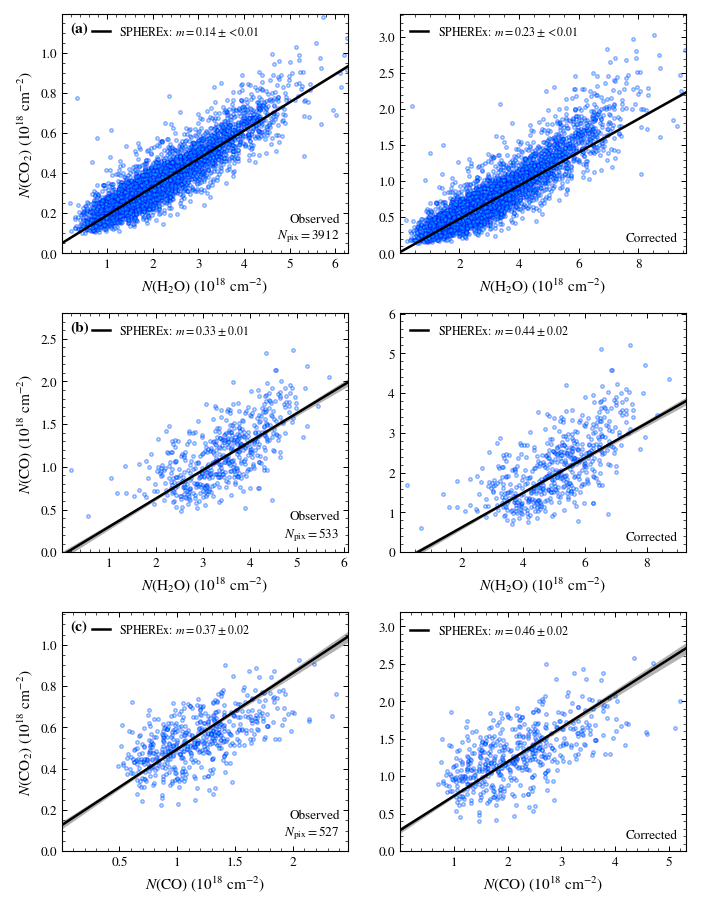

-> spherex_ice_ice.pdf / .png, spherex_ice_ice_fits.csv


,relation,SPHEREx,N,slope,slope_err,intercept,intercept_err,redchi
0,CO2 vs H2O,observed,3912,0.141,0.001,0.050,0.002,1.146
1,CO2 vs H2O,corrected,3912,0.231,0.002,0.015,0.005,0.392
2,CO vs H2O,observed,533,0.333,0.014,-0.039,0.045,1.513
3,CO vs H2O,corrected,533,0.437,0.019,-0.253,0.085,0.578
4,CO2 vs CO,observed,527,0.369,0.017,0.125,0.018,1.440
5,CO2 vs CO,corrected,527,0.457,0.021,0.277,0.039,0.370


In [22]:
# =========================================================================================
# ICE-ICE RELATIONS OF THE MAP, the same scheme as MOSV4/Ice_formation_fits.ipynb (section 6)
#   rows: CO2 vs H2O, CO vs H2O, CO2 vs CO;  left: fitted columns, right: SPHEREx-corrected
#   fit: straight line y = m x + c with LMFIT, residual = vertical offset / sqrt(sy^2 + m^2 sx^2)
#        (errors on both axes), 10 % floor added to the errors, errors from the LMFIT covariance
#        (scaled by the reduced chi^2), 1-sigma bands from that covariance
#   pixels: both ices S/N >= SX_SNR_MIN and N > SX_N_MIN (on the fitted columns, so both panels
#        show the same pixels), correction flag 0 for both ices (outside the calibrated range the
#        corrected maps are blank)
# =========================================================================================
import os
import lmfit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

SX_CSV      = "ice_maps_Serpens_NIRCam_combined.csv"
NIRSPEC_FITS = None    # e.g. "../MOSV4/ice_formation_fits.csv" to overlay the NIRSpec relations
SX_SNR_MIN  = 5
SX_N_MIN    = {"H2O": 1e17, "CO2": 1e17, "CO": 1e17}
SX_SYS_FLOOR = 0.10
PAIRS = [("H2O", "CO2"), ("H2O", "CO"), ("CO", "CO2")]
LABEL = {"H2O": r"$\mathrm{H_2O}$", "CO2": r"$\mathrm{CO_2}$", "CO": r"$\mathrm{CO}$"}
FIG_W = 7.1
COL = {"fit": "black", "jwst": "#D55E00"}
STYLE = {
    "font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 10,
    "axes.labelsize": 11, "legend.fontsize": 8.5, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.linewidth": 0.8, "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True,
    "ytick.right": True, "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.major.size": 3.5, "ytick.major.size": 3.5, "xtick.minor.size": 2, "ytick.minor.size": 2,
    "xtick.major.width": 0.7, "ytick.major.width": 0.7, "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5, "legend.frameon": False, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15, "pdf.fonttype": 42, "ps.fonttype": 42}


def _residual(p, x, y, xerr, yerr):
    m, c = p["m"].value, p["c"].value
    return (y - m * x - c) / np.sqrt(yerr ** 2 + (m * xerr) ** 2)


def line_fit(x, y, xerr, yerr, sys_floor=SX_SYS_FLOOR):
    """y = m x + c with LMFIT (errors on both axes + the floor).  m, c, errors, covariance."""
    xerr = np.hypot(xerr, sys_floor * x)
    yerr = np.hypot(yerr, sys_floor * y)
    m0, c0 = np.polyfit(x, y, 1)
    p = lmfit.Parameters()
    p.add("m", value=m0)
    p.add("c", value=c0)
    r = lmfit.minimize(_residual, p, args=(x, y, xerr, yerr))
    return dict(m=r.params["m"].value, c=r.params["c"].value, m_err=r.params["m"].stderr,
                c_err=r.params["c"].stderr, cov=r.covar, redchi=r.redchi, n=len(x), x=x, y=y)


def band(f, xx):
    """1-sigma range of the line at xx."""
    s = np.sqrt(f["cov"][0, 0] * xx ** 2 + f["cov"][1, 1] + 2 * xx * f["cov"][0, 1])
    yy = f["m"] * xx + f["c"]
    return yy - s, yy + s


def nirspec_relations(path):
    """NIRSpec ice-ice lines from Ice_formation_fits.ipynb, in the same dict form (or {})."""
    if not path:
        return {}
    if not os.path.exists(path):
        print(f"[info] {path} not found: no NIRSpec lines")
        return {}
    t = pd.read_csv(path).set_index("relation")
    out = {}
    for xi, yi in PAIRS:
        key = f"{yi} vs {xi}"
        if key in t.index:
            r = t.loc[key]
            cmc = r["cov_mc"] if "cov_mc" in r else 0.0
            out[(xi, yi)] = dict(m=r["slope"], c=r["intercept"], m_err=r["slope_err"],
                                 cov=np.array([[r["slope_err"] ** 2, cmc], [cmc, r["intercept_err"] ** 2]]))
    return out


def pm2(err):
    return f"{err:.2f}" if round(err, 2) > 0 else "<\\!0.01"


def sx_select(sx, xi, yi):
    m = np.ones(len(sx), bool)
    for sp in (xi, yi):
        m &= sx[f"snr_{sp}"] >= SX_SNR_MIN
        m &= sx[f"N_{sp}"] > SX_N_MIN[sp]
        m &= sx[f"corr_flag_{sp}"] == 0
        m &= np.isfinite(sx[f"N_{sp}_corr"]) & (sx[f"N_{sp}_corr_err"] > 0)
    return m.values


def ice_ice_figure(csv=SX_CSV, nirspec=NIRSPEC_FITS, out="spherex_ice_ice"):
    sx = pd.read_csv(csv)
    jw = nirspec_relations(nirspec)
    fits_ = {}
    for xi, yi in PAIRS:
        m = sx_select(sx, xi, yi)
        for corrected in (False, True):
            suf = "_corr" if corrected else ""
            fits_[(xi, yi, corrected)] = line_fit(
                sx.loc[m, f"N_{xi}{suf}"].values / 1e18, sx.loc[m, f"N_{yi}{suf}"].values / 1e18,
                sx.loc[m, f"N_{xi}{suf}_err"].values / 1e18, sx.loc[m, f"N_{yi}{suf}_err"].values / 1e18)
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(3, 2, figsize=(FIG_W, 9.0))
        for r, (row, (xi, yi)) in enumerate(zip(axes, PAIRS)):
            for k, (ax, corrected) in enumerate(zip(row, (False, True))):
                f = fits_[(xi, yi, corrected)]
                xmax = np.percentile(f["x"], 99.5) * 1.15
                xx = np.linspace(0, xmax, 200)
                ax.scatter(f["x"], f["y"], s=6, color="cyan", alpha=0.35, edgecolor="b", lw=1,
                           zorder=2, rasterized=True)
                lines = [(f, COL["fit"], "SPHEREx")]
                if (xi, yi) in jw:
                    lines.append((jw[(xi, yi)], COL["jwst"], "NIRSpec"))
                for g, col, name in lines:
                    lo, hi = band(g, xx)
                    ax.fill_between(xx, lo, hi, color=col, alpha=0.3, lw=0, zorder=3)
                    ax.plot(xx, g["m"] * xx + g["c"], color=col, lw=1.8, zorder=4,
                            label=rf"{name}: $m = {g['m']:.2f} \pm {pm2(g['m_err'])}$")
                ax.set_xlim(0, xmax)
                ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: "" if abs(v) < 1e-9 else f"{v:g}"))
                ax.set_ylim(0, np.percentile(f["y"], 99.5) * 1.3)
                ax.legend(loc="upper left", bbox_to_anchor=(0.07 if not corrected else 0.0, 1.0),
                          handlelength=1.5, frameon=True, facecolor="white", framealpha=0.9,
                          edgecolor="none")
                if not corrected:
                    ax.text(0.03, 0.97, f"({'abc'[r]})", transform=ax.transAxes, ha="left", va="top",
                            fontsize=11, fontweight="bold", zorder=30,
                            bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
                label = "Corrected" if corrected else f"Observed\n$N_{{\\rm pix}} = {f['n']}$"
                ax.text(0.97, 0.04, label, transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5)
                ax.set_xlabel(rf"$N$({LABEL[xi]}) ($10^{{18}}$ cm$^{{-2}}$)")
                if k == 0:
                    ax.set_ylabel(rf"$N$({LABEL[yi]}) ($10^{{18}}$ cm$^{{-2}}$)")
        fig.subplots_adjust(left=0.09, right=0.97, bottom=0.05, top=0.98, wspace=0.18, hspace=0.25)
        fig.savefig(f"{out}.pdf")
        fig.savefig(f"{out}.png")
        plt.show()
    rows = []
    for (xi, yi, corrected), f in fits_.items():
        row = {"relation": f"{yi} vs {xi}", "SPHEREx": "corrected" if corrected else "observed",
               "N": f["n"], "slope": f["m"], "slope_err": f["m_err"], "intercept": f["c"],
               "intercept_err": f["c_err"], "redchi": f["redchi"]}
        if (xi, yi) in jw:
            row.update({"NIRSpec slope": jw[(xi, yi)]["m"], "SPHEREx / NIRSpec": f["m"] / jw[(xi, yi)]["m"]})
        rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(f"{out}_fits.csv", index=False)
    print(f"-> {out}.pdf / .png, {out}_fits.csv")
    return table


ice_ice_figure().round(3)
